Member 2
## Step 1: Set up

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from tslab import config
from tslab.data import load_market_data
from tslab.team import make_dataset_jpm                 # OUR features (includes the financial sector), not tslab.features
from tslab.validation import walk_forward_splits, describe_splits
from tslab.metrics import compare_models, diebold_mariano, dm_verdict, directional_accuracy_test
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(config.SEED)
print("Target stock:", config.TARGET_TICKER)

Target stock: JPM


## Step 2: The data and the walk-forward folds



In [2]:
frame = load_market_data()                                              # one row per J
dataset = make_dataset_jpm(frame, horizon=1).dropna(subset=["target_return"])
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

print("Rows in the modelling table:", len(dataset))
print("Walk-forward folds         :", len(splits))
print("First test day:", dataset.index[splits[0][1][0]].date(), "| last test day:", dataset.index[splits[-1][1][-1]].date())
describe_splits(splits, dataset.index).head()

Loaded 2989 trading days of JPM, 2015-01-02 to 2026-11-19, with 8 predictor series.
Rows in the modelling table: 2789
Walk-forward folds         : 29
First test day: 2019-10-08 | last test day: 2026-11-18


,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
1,1000,2015-10-16,2019-10-07,63,2019-10-08,2020-01-07
2,1063,2015-10-16,2020-01-07,63,2020-01-08,2020-04-07
3,1126,2015-10-16,2020-04-07,63,2020-04-08,2020-07-08
4,1189,2015-10-16,2020-07-08,63,2020-07-09,2020-10-06
5,1252,2015-10-16,2020-10-06,63,2020-10-07,2021-01-06


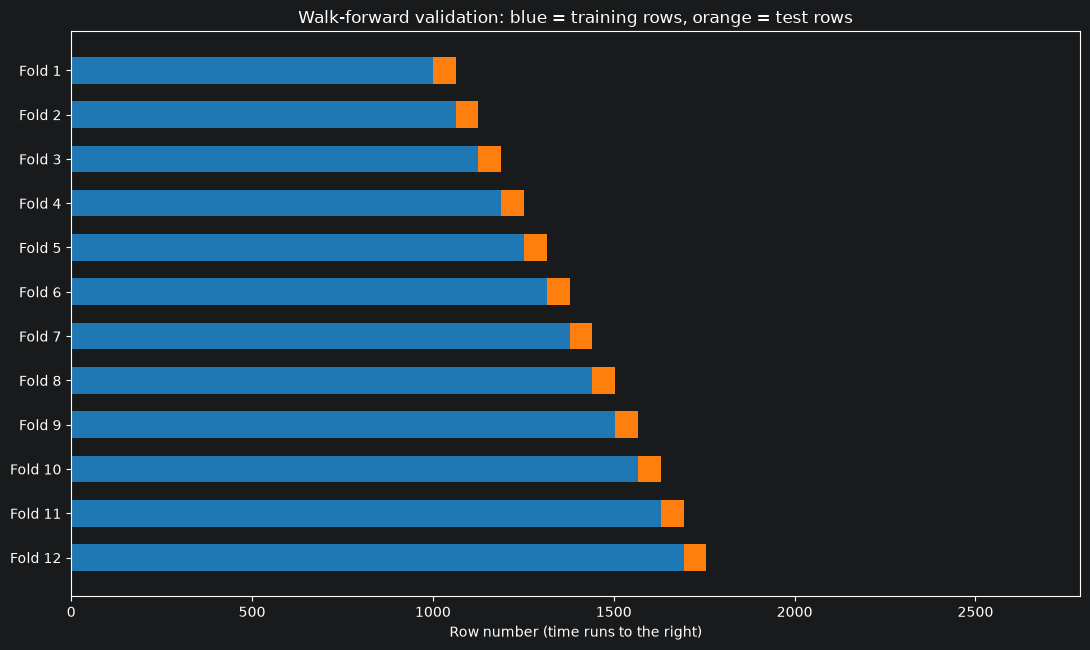

In [3]:
plot_walk_forward_layout(splits, len(dataset))

### Why this test is honest



- The training window only contains data from days before each test block. We use an expanding window and do not shuffle the data, so future information is not used to predict the past.
- Every model is refitted in each fold using only the training data available at that point. This ensures that the model does not learn from the test data.
- The ARIMA order is selected using only the first training block, before any test days are used. This prevents us from choosing a model based on future test results.*

## Step 3: Baseline forecasts



In [4]:
predictions = {}

def empty_series():
    return pd.Series(np.nan, index=dataset.index)

log_close = np.log(frame["Close"])
position_in_frame = {date: i for i, date in enumerate(frame.index)}

drift = empty_series()

for train_idx, test_idx in splits:
    drift.iloc[test_idx] = dataset["target_return"].iloc[train_idx].mean()

predictions["Drift"] = drift

In [5]:
ses = empty_series()
alphas = []

for train_idx, test_idx in splits:
    last_train_date = dataset.index[train_idx[-1]]
    train_prices = frame["Close"].loc[:last_train_date]

    alpha = SimpleExpSmoothing(train_prices, initialization_method="estimated").fit().params["smoothing_level"]
    alphas.append(alpha)


    level = frame["Close"].iloc[0]
    levels = []

    for price in frame["Close"].values:
        level = alpha * price + (1 - alpha) * level
        levels.append(level)

    levels = pd.Series(levels, index=frame.index)

    ses.iloc[test_idx] = np.log(levels.reindex(dataset.index).iloc[test_idx] / dataset["close"].iloc[test_idx])

predictions["Simple exponential smoothing"] = ses

print("Estimated alpha in each fold (first five):", np.round(alphas[:5], 3))

Estimated alpha in each fold (first five): [0.991 0.994 0.841 0.869 0.87 ]


## Step 4: ARIMA



In [6]:
first_train_end_date = dataset.index[splits[0][0][-1]]
first_block = log_close.loc[:first_train_end_date]

rows = []
for p in range(0, 4):
    for q in range(0, 4):
        try:
            result = ARIMA(first_block, order=(p, 1, q)).fit()
            rows.append({"p": p, "d": 1, "q": q, "AIC": result.aic})
        except Exception:
            pass

aic_table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
display(aic_table.head(5))

best_p, _, best_q = aic_table.loc[0, ["p", "d", "q"]].astype(int)
print(f"Chosen order: ARIMA({best_p}, 1, {best_q})")

,p,d,q,AIC
0,0,1,0,-6933.985338
1,1,1,0,-6932.132089
2,0,1,1,-6932.121777
3,2,1,0,-6930.240451
4,0,1,2,-6930.209622


Chosen order: ARIMA(0, 1, 0)


In [7]:
arima = empty_series()

for train_idx, test_idx in splits:
    last_train_pos = position_in_frame[dataset.index[train_idx[-1]]]
    first_test_pos = position_in_frame[dataset.index[test_idx[0]]]
    last_test_pos = position_in_frame[dataset.index[test_idx[-1]]]

    fitted = ARIMA(
        log_close.iloc[: last_train_pos + 1],
        order=(best_p, 1, best_q)
    ).fit()

    carried = fitted.apply(
        log_close.iloc[: last_test_pos + 2],
        refit=False
    )

    one_step = carried.get_prediction(
        start=first_test_pos + 1,
        end=last_test_pos + 1
    ).predicted_mean

    today = log_close.iloc[first_test_pos : last_test_pos + 1].values
    arima.iloc[test_idx] = one_step.values - today

predictions[f"ARIMA({best_p},1,{best_q})"] = arima

The AIC selected ARIMA(0,1,0) as the best model for JPM. This means the model uses one level of differencing (d=1), but has no autoregressive (p=0) or moving-average (q=0) terms. It suggests that JPM's future price movements are best represented by a random walk, where the next price is based on the current price rather than additional patterns from past movements. Therefore, this model is equivalent to the naive forecast in our setup and does not provide evidence that a more complex ARIMA model improves forecasting accuracy.



## Step 5: ARMA(1,0) and ARMAX with our predictors



In [8]:

# Calculate daily changes for the external predictors
predictor_changes = pd.DataFrame(index=frame.index)

for name in ["SP500", "TECH", "GOLD", "BRENT", "USD", "VIX", "FIN"]:
    predictor_changes[name] = np.log(frame[name]).diff()

# US10Y is a yield, so use the difference rather than log difference
predictor_changes["US10Y"] = frame["US10Y"].diff()

# Lag predictors by one day to avoid look-ahead bias
exog_all = predictor_changes.shift(1)

stock_return = log_close.diff()

FIRST_USABLE = 2


def walk_forward_arma(use_exog, ar_order=1):
    """
    Generate one-step-ahead walk-forward forecasts using ARMA,
    with or without external predictors.
    """
    output = empty_series()

    for train_idx, test_idx in splits:
        last_train_pos = position_in_frame[dataset.index[train_idx[-1]]]
        first_test_pos = position_in_frame[dataset.index[test_idx[0]]]
        last_test_pos = position_in_frame[dataset.index[test_idx[-1]]]

        # Fit the model using training data only
        y_train = stock_return.iloc[FIRST_USABLE:last_train_pos + 1]
        x_train = (
            exog_all.iloc[FIRST_USABLE:last_train_pos + 1]
            if use_exog else None
        )

        fitted = SARIMAX(
            y_train,
            exog=x_train,
            order=(ar_order, 0, 0),
            trend="c"
        ).fit(disp=False)

        # Apply fitted parameters through the test period
        y_all = stock_return.iloc[FIRST_USABLE:last_test_pos + 2]
        x_all = (
            exog_all.iloc[FIRST_USABLE:last_test_pos + 2]
            if use_exog else None
        )

        carried = fitted.apply(y_all, exog=x_all, refit=False)

        # Obtain one-step-ahead predictions
        start = first_test_pos + 1 - FIRST_USABLE
        end = last_test_pos + 1 - FIRST_USABLE

        output.iloc[test_idx] = (
            carried.get_prediction(start=start, end=end).predicted_mean.values
        )

    return output


# Generate ARMA and ARMAX forecasts
predictions["ARMA(1,0)"] = walk_forward_arma(use_exog=False)
predictions["ARMAX"] = walk_forward_arma(use_exog=True)


The predictors are shifted by one day so that each forecast uses information available on the previous trading day, preventing the model from using future information (look-ahead bias).

In [9]:
predictions["Naive (no change)"] = pd.Series(
    0.0,
    index=dataset.index
)



## Step 6: Compare every model with the naive forecast



In [10]:
if not predictions:
    print("No models yet: fill in Steps 3 to 5 first.")
else:
    scores = compare_models(dataset, predictions)
    display(scores.round(4))

,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),2.9737,2.0128,1.2504,NaN,0.0000
Drift,2.9723,2.0060,1.2481,0.5344,0.0007
Simple exponential smoothing,2.9797,2.0184,1.2537,0.4902,-0.0062
"ARIMA(0,1,0)",2.9737,2.0128,1.2504,NaN,0.0000
"ARMA(1,0)",2.9816,2.0193,1.2558,0.5137,-0.0092
ARMAX,3.0005,2.0294,1.2635,0.5271,-0.0145
Naive (no change),2.9737,2.0128,1.2504,NaN,0.0000


In [11]:

scored_rows = pd.concat(predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]

rows = []

for name, series in predictions.items():
    forecast = series.loc[scored_rows]

    statistic, p_dm = diebold_mariano(
        actual,
        forecast,
        np.zeros(len(scored_rows))
    )

    if (np.abs(forecast) > 1e-8).sum() == 0:
        hit_rate = np.nan
        p_dir = np.nan
    else:
        hit_rate, p_dir = directional_accuracy_test(
            actual,
            forecast
        )

    rows.append({
        "Model": name,
        "DM statistic vs naive": statistic,
        "DM p-value": p_dm,
        "Verdict": dm_verdict(statistic, p_dm),
        "Hit rate": hit_rate,
        "Hit rate p-value (vs 50%)": p_dir
    })

dm_table = pd.DataFrame(rows).set_index("Model").round(4)

display(dm_table)


,DM statistic vs naive,DM p-value,Verdict,Hit rate,Hit rate p-value (vs 50%)
Model,,,,,
Drift,-0.4113,0.6809,No significant difference,0.5344,0.0039
Simple exponential smoothing,1.0161,0.3097,No significant difference,0.4902,0.4215
"ARIMA(0,1,0)",1.2113,0.2259,No significant difference,NaN,NaN
"ARMA(1,0)",1.1090,0.2676,No significant difference,0.5137,0.2564
ARMAX,1.0358,0.3004,No significant difference,0.5271,0.0232
Naive (no change),NaN,NaN,Significantly WORSE than naive,NaN,NaN


Drift achieved the lowest RMSE (2.9723), MAE (2.0060) and MAPE (1.2481%) among the classical models. However, its DM p-value of 0.6809 is above 0.05, meaning its improvement over the naive forecast is not statistically significant. Although Drift and ARMAX achieved directional accuracy significantly above 50%, none of the classical models demonstrated a statistically significant forecasting improvement over the naive benchmark. ARIMA(0,1,0) produced effectively zero return forecasts, explaining why its directional accuracy was unavailable.



## Step 7: A forecast that looks perfect but is not



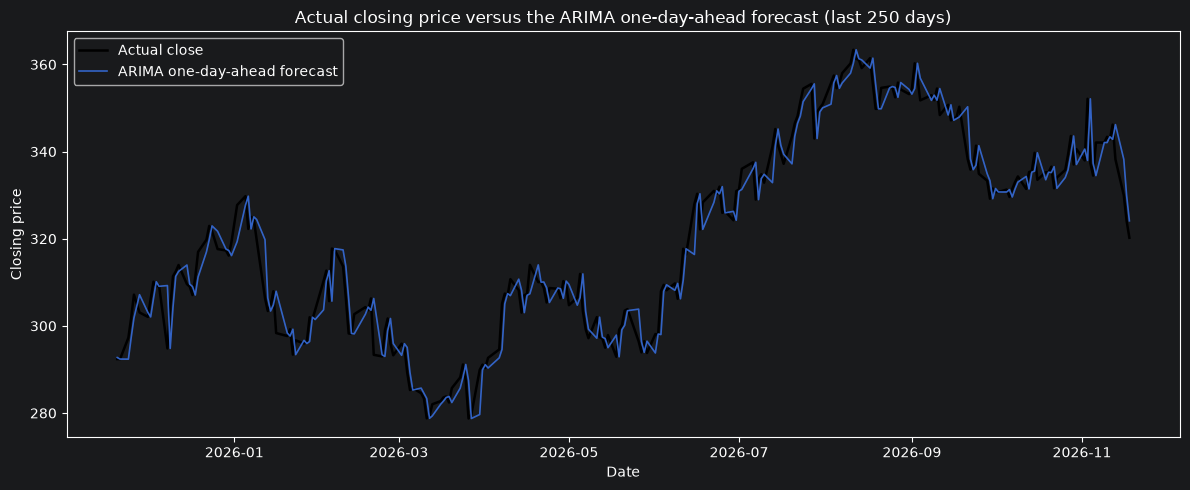

In [12]:
scored = dataset.loc[scored_rows]
arima_price = scored["close"] * np.exp(predictions[f"ARIMA({best_p},1,{best_q})"].loc[scored_rows])

next_day_labels = scored.index.to_series().shift(-1)
plot_price_forecasts(
    dates=scored.index, actual=scored["target_close"].values,
    forecasts={"ARIMA one-day-ahead forecast": arima_price.values},
    title="Actual closing price versus the ARIMA one-day-ahead forecast (last 250 days)",
    last_n=250,
)

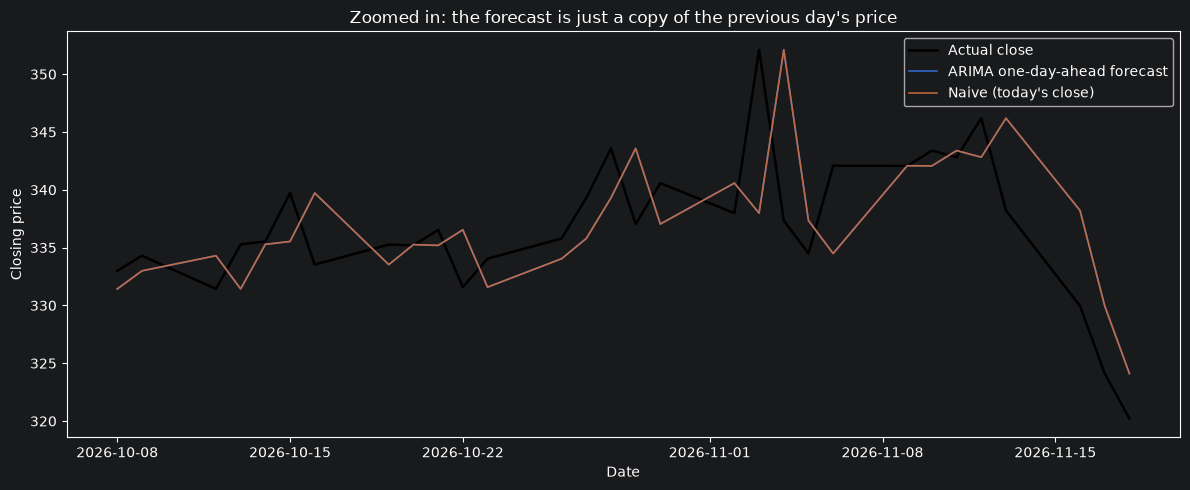

In [13]:
plot_price_forecasts(
    dates=scored.index, actual=scored["target_close"].values,
    forecasts={"ARIMA one-day-ahead forecast": arima_price.values, "Naive (today's close)": scored["close"].values},
    title="Zoomed in: the forecast is just a copy of the previous day's price",
    last_n=30,
)

The ARIMA forecast appears almost perfect because its predicted closing prices closely follow the actual JPM closing prices. However, this is misleading because ARIMA(0,1,0) is equivalent to the naive forecast, meaning it simply uses the previous day's closing price to predict the next day's price rather than identifying a genuinely useful forecasting pattern.

## Step 8: Residual diagnostics



                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.0003   2.73e-06    104.498      0.000       0.000       0.000


,Statistic,p-value
5,59.892900,1.278999e-11
10,128.703950,8.584963e-23
21,156.219191,1.146200e-22


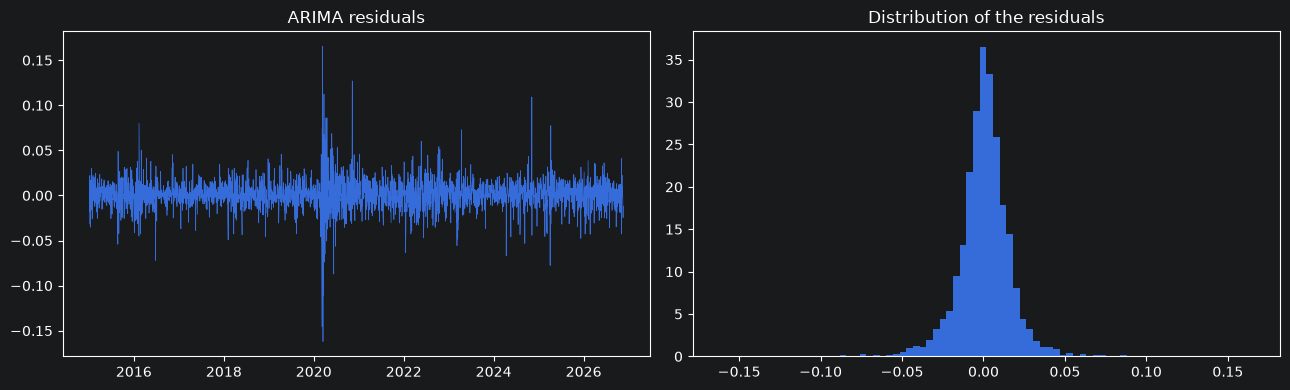

In [14]:
final_arima = ARIMA(log_close.to_numpy(), order=(best_p, 1, best_q)).fit()
print(final_arima.summary().tables[1])

residuals = pd.Series(final_arima.resid[1:], index=log_close.index[1:])
display(acorr_ljungbox(residuals, lags=[5, 10, 21], return_df=True).rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(residuals, linewidth=0.5); axes[0].set_title("ARIMA residuals")
axes[1].hist(residuals, bins=80, density=True); axes[1].set_title("Distribution of the residuals")
plt.tight_layout(); plt.show()

The Ljung–Box test indicates that significant autocorrelation remains in the residuals at lags 5, 10 and 21, suggesting that the model has not captured all the patterns in JPM's returns.



## Step 9: What happens 63 days ahead?



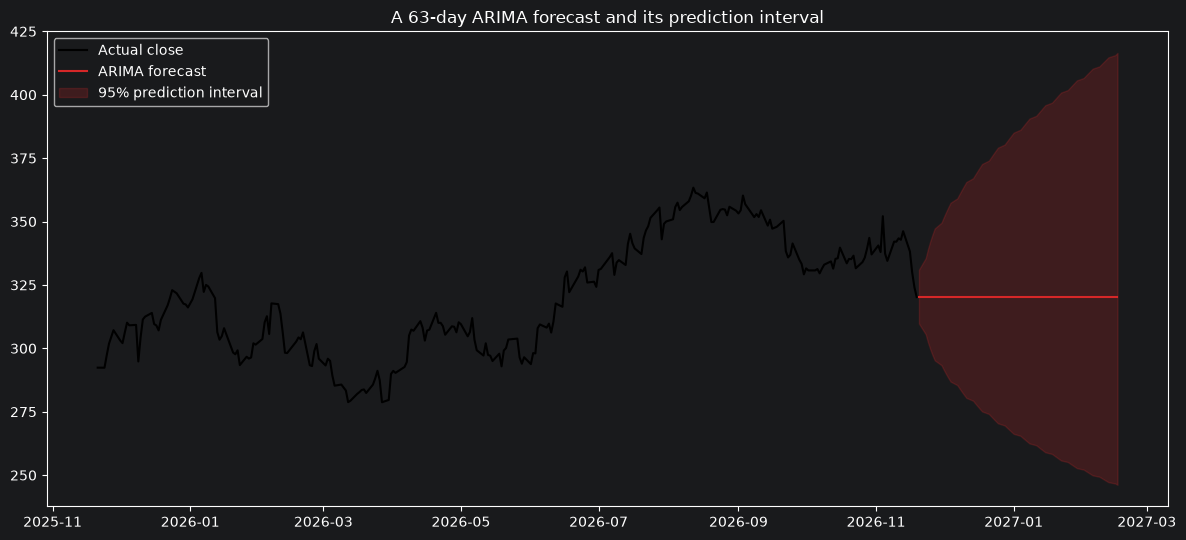

Last actual close          : 320.22
Forecast in 63 days        : 320.22
95% interval in 63 days    : 246.20 to 416.49


In [15]:
horizon = 63
long_forecast = final_arima.get_forecast(steps=horizon)
mean_log_price = long_forecast.predicted_mean
interval = long_forecast.conf_int(alpha=0.05)

future_dates = pd.bdate_range(start=frame.index[-1] + pd.offsets.BDay(1), periods=horizon)
forecast_price = pd.Series(np.exp(mean_log_price), index=future_dates)
lower = pd.Series(np.exp(interval[:, 0]), index=future_dates)
upper = pd.Series(np.exp(interval[:, 1]), index=future_dates)

recent = frame["Close"].iloc[-250:]
plt.figure(figsize=(12, 5.5))
plt.plot(recent, color="black", label="Actual close")
plt.plot(forecast_price, color="tab:red", label="ARIMA forecast")
plt.fill_between(future_dates, lower, upper, color="tab:red", alpha=0.2, label="95% prediction interval")
plt.title("A 63-day ARIMA forecast and its prediction interval")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Last actual close          : {frame['Close'].iloc[-1]:.2f}")
print(f"Forecast in 63 days        : {forecast_price.iloc[-1]:.2f}")
print(f"95% interval in 63 days    : {lower.iloc[-1]:.2f} to {upper.iloc[-1]:.2f}")

## Step 10: Save the predictions



In [16]:

if predictions:
    os.makedirs(config.OUTPUT_DIR, exist_ok=True)


    saved = pd.concat(predictions, axis=1)


    arima_col = f"ARIMA({best_p},1,{best_q})"
    if arima_col in saved.columns:
        saved = saved.rename(columns={arima_col: "ARIMA"})


    required_columns = [
        "Naive (no change)",
        "Drift",
        "Simple exponential smoothing",
        "ARIMA",
        "ARMA(1,0)",
        "ARMAX"
    ]

    saved = saved[required_columns]


    saved.to_csv(config.OUTPUT_DIR / "predictions_classical.csv")

    print("Saved", saved.dropna().shape[0], "complete rows")
    print("Columns:", list(saved.columns))

else:
    print("Nothing saved yet: no models.")


Saved 1789 complete rows
Columns: ['Naive (no change)', 'Drift', 'Simple exponential smoothing', 'ARIMA', 'ARMA(1,0)', 'ARMAX']


## Conclusion

The Drift model performed best among the classical forecasting models, recording the lowest RMSE of $2.9723, MAE of $2.0060 and MAPE of 1.2481%. However, its Diebold-Mariano p-value of 0.6809 was above 0.05, meaning that its improvement over the naive forecast was not statistically significant. None of the classical models significantly outperformed the naive forecast, suggesting that more complex forecasting methods did not provide a reliable improvement in predicting JPM's daily stock movements. Although Drift and ARMAX achieved directional accuracy above 50% at statistically significant levels, this did not translate into significantly lower forecasting errors. For a portfolio manager, this means that relying on these classical models alone may not provide a meaningful forecasting advantage over simply assuming that the next day's price will remain unchanged. The naive forecast therefore remains a useful benchmark, and more advanced analysis or additional information may be needed to improve investment decisions.